# ASRS LoRA Classifier

**Task:** NASA's Aviation Safety Reporting System (ASRS) collects incident reports written by pilots, controllers and mechanics. Each report is tagged by analysts with one or more *anomaly* categories (e.g. "Ground Incursion Runway", "Aircraft Equipment Problem Critical"). Goal: predict these categories from the narrative text alone (multi-label classification, 46 labels).

**Approach:** fine-tune a small open LLM (Qwen3-0.6B) with LoRA and a classification head, and compare it to a TF-IDF baseline and a prompted frontier model.

**Data:** 85k reports from 2010 to 2025, split by date (train ≤2022, val 2023, test 2024–2025).

**Metric:** macro-F1 (every label counts equally, so rare categories matter).

| Model | Val macro-F1 | Test macro-F1 |
| --- | --- | --- |
| TF-IDF + logistic regression | 0.55 | – |
| Frontier model (prompted) | – | – |
| Qwen3-0.6B + LoRA | – | – |

---

## 0. Setup

In [2]:
%load_ext autoreload
%autoreload 2

import json
import time
import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import f1_score

from transformers import AutoTokenizer
import matplotlib.pyplot as plt

from asrs_lora_classifier.loader import REPO_ROOT, load_all

SEED = 42
RAW_DIR = REPO_ROOT / "data" / "raw" / "nasa"
DATA_DIR = REPO_ROOT / "data" / "processed"
RESULTS_DIR = REPO_ROOT / "results"

---

## 1. Raw data: from 32 CSVs to one table

### First look at the data: loading one file and looking at it

In [3]:
path = RAW_DIR / "asrs_2010_H1.csv"
raw = pd.read_csv(path, header=None, dtype=str, nrows=5)
print(raw.shape)
raw.iloc[:, :6]

(5, 126)


,0,1,2,3,4,5
0,,Time,Time,Place,Place,Place
1,ACN,Date,Local Time Of Day,Locale Reference,State Reference,Relative Position.Angle.Radial
2,866849,201001,1201-1800,ZHU.ARTCC,TX,NaN
3,866859,201001,1201-1800,ZAU.ARTCC,IL,NaN
4,866866,201001,1801-2400,ZHU.ARTCC,TX,NaN


### We build the column names from the groups (row 0) and the fields (row 1)
By taking row 0 and 1, pairing them column by column and transforming each pair to a column name of the form {group} | {field}

Example:
- Row 0, Col 2 = Time
- Row 1, Col 2 = Local Time Of Day
- Therefore we get the new column name: "Time | Local Time Of Day"

The group cell above `ACN` is a single space, not empty, so we `.strip()` before comparing to `""`.

In [4]:
print(repr(raw.iloc[0, 0]))

groups = raw.iloc[0].str.strip()
fields = raw.iloc[1].str.strip()

names = []
for g, f in zip(groups, fields):
    if g == "":
        names.append(f)
    else:
        names.append(f"{g} | {f}")

names[:6]

' '


['ACN',
 'Time | Date',
 'Time | Local Time Of Day',
 'Place | Locale Reference',
 'Place | State Reference',
 'Place | Relative Position.Angle.Radial']

In [5]:
len(names) == len(set(names))

True

In [6]:
[n for n in names if "Anomaly" in n or "Narrative" in n]

['Events | Anomaly', 'Report 1 | Narrative', 'Report 2 | Narrative']

### Load the full file, real column names, only what we need

In [7]:
df = pd.read_csv(path, header=None, skiprows=2, names=names, dtype=str)
df.shape

(2814, 126)

In [8]:
cols = {
    "ACN": "acn",
    "Time | Date": "date",
    "Events | Anomaly": "anomaly",
    "Report 1 | Narrative": "narrative",
}
df = df[list(cols)].rename(columns=cols)
df.head()

,acn,date,anomaly,narrative
0,866849,201001,ATC Issue All Types; Deviation / Discrepancy -...,Ocean West and Offshore West/Central were comb...
1,866859,201001,ATC Issue All Types; Deviation / Discrepancy -...,Aircraft X had a flight plan in URET (user req...
2,866866,201001,ATC Issue All Types; Airspace Violation All Ty...,I was working D-79 when Aircraft X reported ov...
3,866977,201001,Aircraft Equipment Problem Critical,Descending to FL340 we got a Green Hydraulic L...
4,866984,201001,Aircraft Equipment Problem Critical; Inflight ...,On climbout at approximately 15;000 FT noticed...


In [9]:
df.isna().sum()

acn           0
date          0
anomaly      12
narrative     0
dtype: int64

We can see that we get 12 missing anomalies. These rows will be dropped in the next step.

### From the anomaly string to a list of labels

In [10]:
# Drop the 12 reports with no anomaly
df = df.dropna(subset=["anomaly"])
df.shape

(2802, 4)

In [11]:
len(set(df["anomaly"]))

685

685 distinct values for 2,802 reports: **the field is not one label but a ;-separated list of labels**, so we need to parse it.

In [12]:
ORPHANS = {"Critical", "Less Severe"}

def parse_anomaly(s):
    labels = []
    for part in s.split(";"):
        part = part.strip()
        if part == "":
            continue
        if part in ORPHANS:
            assert labels[-1] == "Conflict Ground Conflict", (s, part)
            labels[-1] = f"{labels[-1]} {part}"
        else:
            labels.append(part)
    return labels

Splitting on ; breaks one label in two: Conflict Ground Conflict; Critical is really the single label Conflict Ground Conflict Critical. parse_anomaly re-attaches these orphan fragments, and the assert fails loudly if an orphan ever follows a different label.

In [13]:
parse_anomaly("ATC Issue All Types; Conflict Ground Conflict; Critical; Ground Incursion Runway")

['ATC Issue All Types',
 'Conflict Ground Conflict Critical',
 'Ground Incursion Runway']

In [14]:
df["labels"] = df["anomaly"].apply(parse_anomaly)
df["labels"].explode().value_counts()

labels
Deviation / Discrepancy - Procedural Published Material / Policy     1014
Aircraft Equipment Problem Critical                                   868
ATC Issue All Types                                                   680
Aircraft Equipment Problem Less Severe                                435
Deviation / Discrepancy - Procedural Clearance                        386
Deviation - Track / Heading All Types                                 213
Conflict Airborne Conflict                                            212
Inflight Event / Encounter Weather / Turbulence                       156
Deviation / Discrepancy - Procedural FAR                              140
Deviation / Discrepancy - Procedural Maintenance                      112
Deviation - Altitude Excursion From Assigned Altitude                 107
Airspace Violation All Types                                           93
Conflict NMAC                                                          93
Inflight Event / Encounter Loss

In [15]:
counts = df["labels"].explode().value_counts()
"Critical" in counts.index, "Less Severe" in counts.index

(False, False)

### One function for one file

Same steps wrapped in a function. This is the version now in `src/asrs_lora_classifier/loader.py`.

In [16]:
def load_file(path):
    header = pd.read_csv(path, header=None, dtype=str, nrows=2)
    groups = header.iloc[0].str.strip()
    fields = header.iloc[1].str.strip()
    names = [f if g == "" else f"{g} | {f}" for g, f in zip(groups, fields)]

    df = pd.read_csv(path, header=None, skiprows=2, names=names, dtype=str)
    df = df[list(cols)].rename(columns=cols)
    df["file"] = path.name
    return df

In [17]:
load_file(path).shape

(2814, 5)

### All 32 files

In [18]:
paths = sorted(RAW_DIR.glob("*.csv"))
len(paths)

32

In [19]:
frames = [load_file(p) for p in paths]
all_df = pd.concat(frames, ignore_index=True)
all_df.shape

(85104, 5)

### Look at duplicates

In [20]:
all_df["acn"].duplicated().sum()

np.int64(0)

0 duplicate ACNs across the 32 files. `load_all()` asserts this.

### Clean the full table and check the dates

In [21]:
all_df.isna().sum()

acn           0
date          0
anomaly      61
narrative     0
file          0
dtype: int64

In [22]:
all_df = all_df.dropna(subset=["anomaly", "narrative"])
all_df["labels"] = all_df["anomaly"].apply(parse_anomaly)
all_df.shape

(85043, 6)

In [23]:
all_df["year"] = all_df["date"].str[:4].astype(int)
file_year = all_df["file"].str[5:9].astype(int)
(file_year != all_df["year"]).sum()

np.int64(26)

In [24]:
all_df.groupby("year").size()

year
2002       1
2010    5483
2011    5635
2012    5053
2013    4477
2014    4574
2015    5972
2016    5406
2017    5211
2018    5657
2019    6426
2020    4981
2021    4571
2022    5451
2023    4590
2024    5427
2025    6128
dtype: int64

We found that there are 26 rows that show a mismatch between their year and the year in their filename. Therefore we will look at them.

In [25]:
mismatch = all_df[file_year != all_df["year"]]
mismatch[["acn", "date", "file"]]

,acn,date,file
31233,1777197,202012,asrs_2015_H2.csv
55888,1780556,202101,asrs_2020_H1.csv
55889,1780849,202101,asrs_2020_H1.csv
55890,1782173,202101,asrs_2020_H1.csv
55894,1790003,202102,asrs_2020_H1.csv
55897,1795476,202101,asrs_2020_H1.csv
55898,1813200,202106,asrs_2020_H1.csv
55899,1818480,202106,asrs_2020_H1.csv
58933,1801444,202108,asrs_2020_H2.csv
58935,1823047,202107,asrs_2020_H2.csv


26 reports sit in a file whose half-year doesn’t match their own date (an export quirk). We trust the report’s date column, so these reports keep their real year. One report is dated 2002, before our 2010 cutoff, and is dropped.

In [26]:
all_df = all_df[all_df["year"] >= 2010]
all_df.shape

(85042, 7)

Everything above is now `load_all()`. From here on we use it.

In [27]:
df = load_all()
assert len(df) == len(all_df), "loader.py and the notebook disagree"
df.shape

(85042, 7)

---

## 2. EDA: labels, drift, narrative lengths

### 2.1 What one example looks like

In [28]:
ex = df.sample(1, random_state=SEED).iloc[0]
print(ex["labels"], "\n")
print(ex["narrative"][:1500])

['Deviation / Discrepancy - Procedural Hazardous Material Violation', 'Deviation / Discrepancy - Procedural Published Material / Policy'] 

There was a 4 box QuickPak shipment that arrived in ZZZ with at least 1 box marked as containing the dangerous goods and dry ice. The DSTG (Departure Staging Guide) did not show any dangerous goods listed on the flight. Even if the dry ice amount is within range of being considered an exempted amount not requiring a pilot notification form; I'm pretty sure these commodities should still be listed on the loading paperwork. If these are not listed on the flight manifest; we do not know they are onboard for proper segregation or how much dangerous goods are being transported.


### 2.2 How frequent is each label? (train years only)

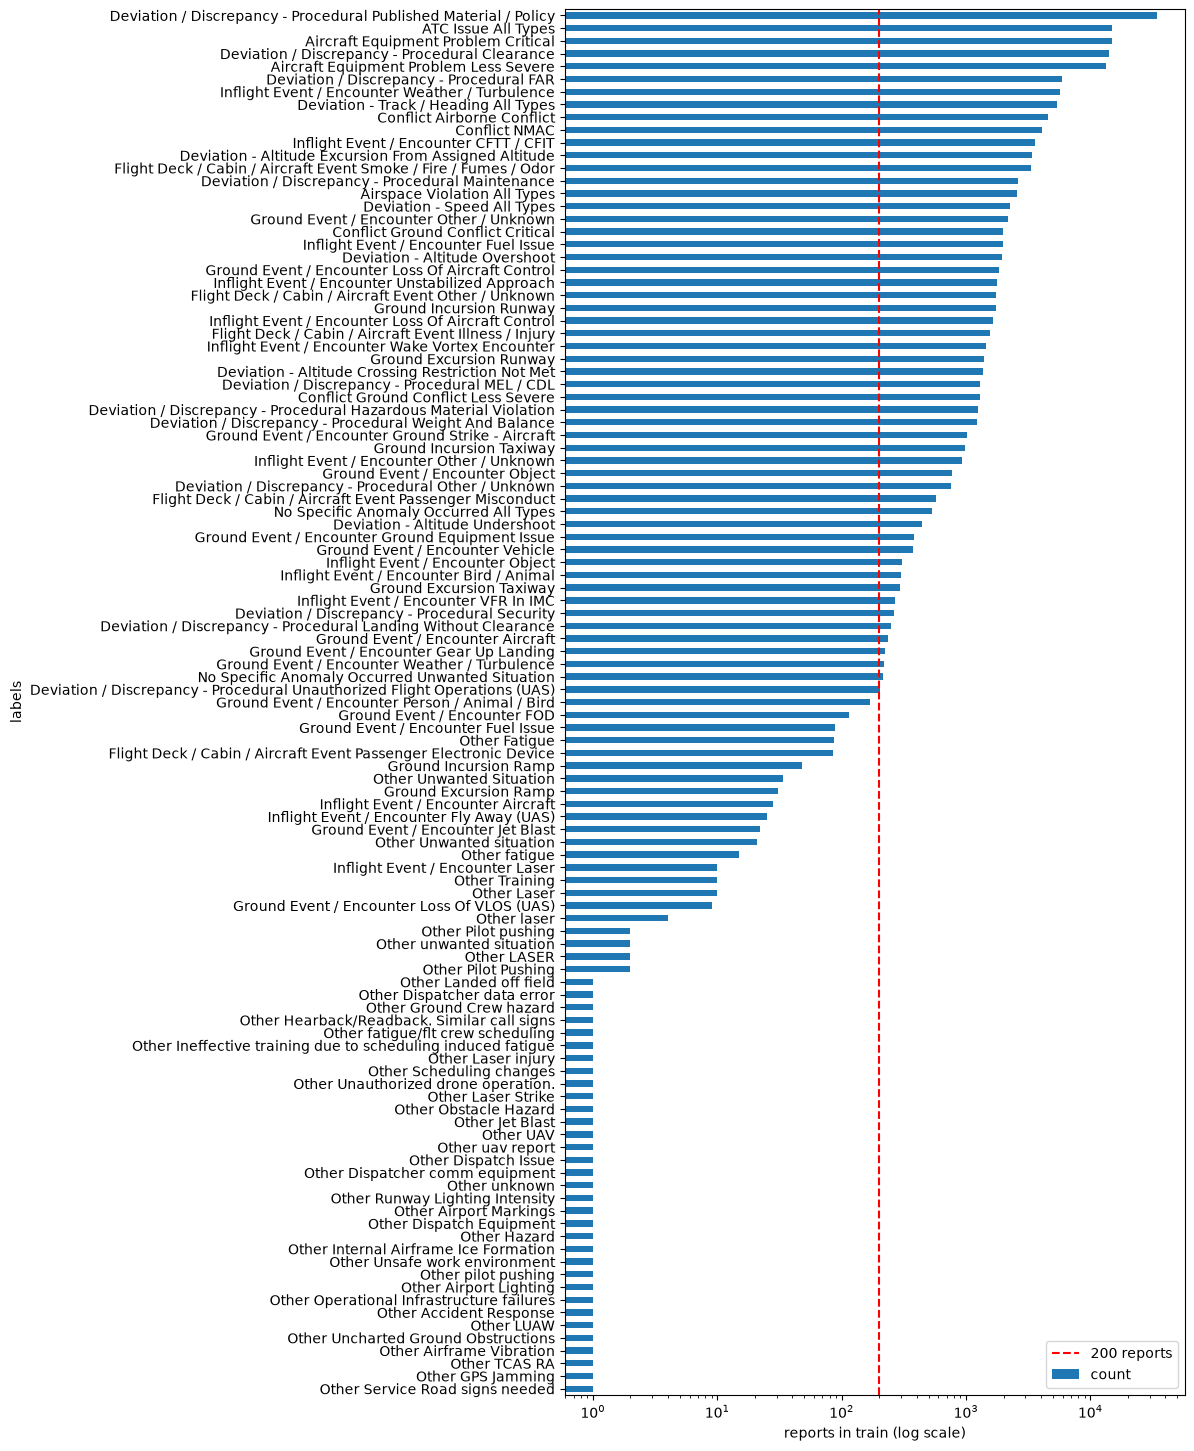

In [29]:
eda_train = df[df["year"] <= 2022]
counts = eda_train["labels"].explode().value_counts()

fig, ax = plt.subplots(figsize=(8, 18))
counts.sort_values().plot.barh(ax=ax)
ax.axvline(200, color="red", ls="--", label="200 reports")
ax.set_xscale("log")
ax.set_xlabel("reports in train (log scale)")
ax.legend()
plt.show()

- Only 54 of the 109 labels pass the red dashed line (have at least 200 reports).
- We can observe a long list of rare labels all at the 10**0 log scale (1 report): "Other Landed off field", "Other Dispatcher data error", "Other Ground Crew hazard", ... 

### 2.3 How many labels per report, and does it change over time?

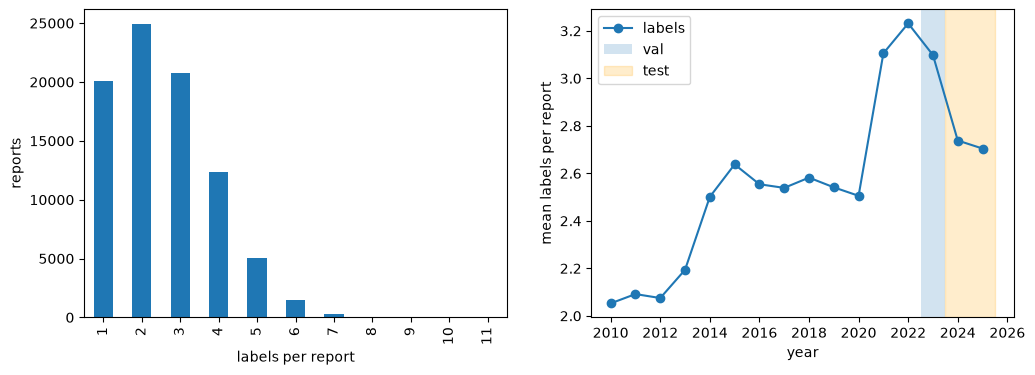

In [30]:
n_labels = df["labels"].str.len()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
n_labels.value_counts().sort_index().plot.bar(ax=a1)
a1.set_xlabel("labels per report"); a1.set_ylabel("reports")

n_labels.groupby(df["year"]).mean().plot(ax=a2, marker="o")
a2.axvspan(2022.5, 2023.5, alpha=0.2, label="val")
a2.axvspan(2023.5, 2025.5, alpha=0.2, color="orange", label="test")
a2.set_ylabel("mean labels per report"); a2.legend()
plt.show()

- Most reports have 2 to 3 labels
- The mean of labels per report has risen recent years from 2020: val and test sets are denser than train.
- The mean number of labels per report rises in two steps: about 2.1 (2010-2013), about 2.5 (2014-2020), then about 3.1 (2021-2023), before dropping to 2.7 in 2024-2025. Validation (2023) is denser than most of train, which will affect the per-label thresholds.

### 2.4 Labels that appear late.

These are examples of labels that disappear or appear over time.

In [31]:
exploded = df.explode("labels")
per_year = pd.crosstab(exploded["labels"], exploded["year"])
per_year.loc[["Deviation / Discrepancy - Procedural Landing Without Clearance",
              "No Specific Anomaly Occurred All Types",
              "No Specific Anomaly Occurred Unwanted Situation"]]

year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
labels,,,,,,,,,,,,,,,,
Deviation / Discrepancy - Procedural Landing Without Clearance,17,19,10,13,17,33,23,16,28,25,29,10,10,2,7,6
No Specific Anomaly Occurred All Types,81,45,44,51,80,80,25,20,22,31,44,4,2,5,2,5
No Specific Anomaly Occurred Unwanted Situation,0,0,0,0,0,0,0,0,0,0,39,93,81,87,62,92


"No Specific Anomaly Occurred Unwanted Situation" first appears in 2020, exactly when "No Specific Anomaly Occurred All Types" collapses (44 reports in 2020, 4 in 2021). This looks like a taxonomy change: analysts replaced one label with the other. "Landing Without Clearance" also becomes rare from 2021 (2 reports in 2023), which is why it fails the validation threshold below.

In [32]:
first_year = per_year.gt(0).idxmax(axis=1)
first_year[first_year > 2010].sort_values()

labels
Other Pilot pushing                                                          2011
Other pilot pushing                                                          2011
Other fatigue                                                                2011
Other Unwanted situation                                                     2011
Other Training                                                               2011
Other Airport Lighting                                                       2011
Other Accident Response                                                      2011
Other Operational Infrastructure failures                                    2011
Other unknown                                                                2011
Other Dispatch Equipment                                                     2012
Other Airport Markings                                                       2012
Other Internal Airframe Ice Formation                                        2012
Other Run

In [33]:
structured = first_year[~first_year.index.str.startswith("Other ")]
late = structured[structured > 2010].sort_values()
pd.DataFrame({
    "first_year": late,
    "total": per_year.loc[late.index].sum(axis=1),
})

,first_year,total
labels,,
Ground Event / Encounter Weather / Turbulence,2014,575
Deviation / Discrepancy - Procedural Unauthorized Flight Operations (UAS),2020,713
Ground Event / Encounter Fuel Issue,2020,162
Ground Event / Encounter Ground Equipment Issue,2020,968
Ground Event / Encounter Jet Blast,2020,67
Ground Incursion Ramp,2020,197
Inflight Event / Encounter Aircraft,2020,37
Inflight Event / Encounter Fly Away (UAS),2020,58
Inflight Event / Encounter Laser,2020,13


UAS appears in 2020 and ground weather/turbulence in 2014, so the model sees fewer years of examples for these.

### 2.5 How long are narratives? (in words for now, tokens come in section 5)

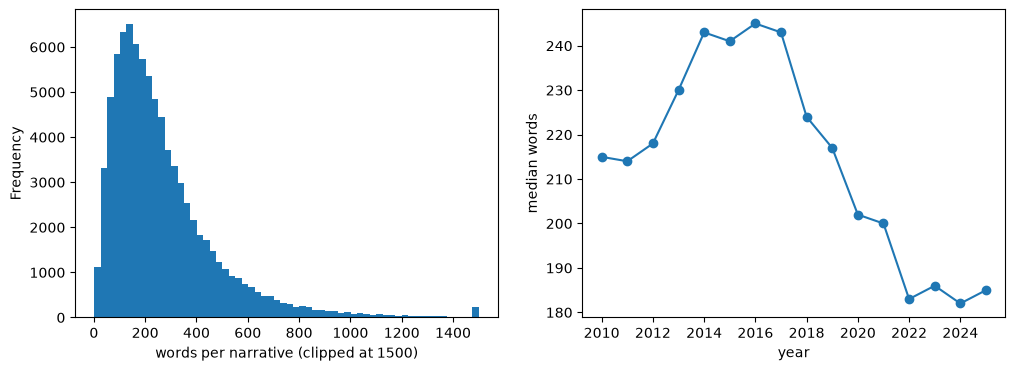

count    85042.000000
mean       268.513923
std        216.148719
min          2.000000
25%        125.000000
50%        214.000000
75%        344.000000
max       2345.000000
Name: narrative, dtype: float64


In [34]:
words = df["narrative"].str.split().str.len()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
words.clip(upper=1500).plot.hist(bins=60, ax=a1)
a1.set_xlabel("words per narrative (clipped at 1500)")
words.groupby(df["year"]).median().plot(ax=a2, marker="o")
a2.set_ylabel("median words")
plt.show()
print(words.describe())

- We can see that the median is 214 words and we have a long right tail on the plot.
- In the second plot we can see that narratives get shorter after 2017, moving from a median of 245 to 185 words.

### 2.6 Choosing the label rule.

In [35]:
len(counts), (counts >= 200).sum()

(109, np.int64(54))

The dataset contains 109 distinct labels in train and 54 with at least 200 reports.

In [36]:
counts[(counts >= 100) & (counts < 400)]

labels
Ground Event / Encounter Ground Equipment Issue                              382
Ground Event / Encounter Vehicle                                             376
Inflight Event / Encounter Object                                            305
Inflight Event / Encounter Bird / Animal                                     299
Ground Excursion Taxiway                                                     296
Inflight Event / Encounter VFR In IMC                                        267
Deviation / Discrepancy - Procedural Security                                263
Deviation / Discrepancy - Procedural Landing Without Clearance               250
Ground Event / Encounter Aircraft                                            237
Ground Event / Encounter Gear Up Landing                                     222
Ground Event / Encounter Weather / Turbulence                                220
No Specific Anomaly Occurred Unwanted Situation                              213
Deviation / Discrepan

#### Check that a label count of 200 is a good cutoff for the labels we will keep

In [37]:
keep = counts[counts >= 200].index
eda_val = df[df["year"] == 2023]
val_counts = eda_val["labels"].explode().value_counts()
val_counts.reindex(keep, fill_value=0).sort_values().head(10)

labels
Deviation / Discrepancy - Procedural Landing Without Clearance     2
No Specific Anomaly Occurred All Types                             5
Deviation / Discrepancy - Procedural Security                      7
Inflight Event / Encounter VFR In IMC                              9
Deviation / Discrepancy - Procedural Other / Unknown              10
Ground Event / Encounter Aircraft                                 13
Flight Deck / Cabin / Aircraft Event Passenger Misconduct         17
Ground Event / Encounter Gear Up Landing                          18
Inflight Event / Encounter Object                                 23
Ground Event / Encounter Vehicle                                  25
Name: count, dtype: int64

We apply a new rule with two conditions:
1. ≥ 200 in train (enough to learn)
2. ≥ 20 in validation (enough to measure)

In [38]:
val_aligned = val_counts.reindex(counts.index, fill_value=0)
rule = (counts >= 200) & (val_aligned >= 20)
final_labels = counts[rule].index.tolist()
len(final_labels)

46

Free-text `Other ...` labels (written by reporters, not real ASRS categories) are also excluded explicitly in `build_label_set`. None of them passes the thresholds anyway, so the final set stays at 46 labels.

### EDA takeaways
- **Imbalanced labels:** 109 raw labels with a long tail. We keep 46 that have enough examples to learn (≥200 in train) and to measure (≥20 in val). Macro-F1 is the right metric because it weights these rare labels equally.
- **Multi-label:** most reports have 2 to 3 labels, so each label is an independent yes/no decision (sigmoid per label, not softmax).
- **Drift over time:** labels per report increase, some labels appear or get replaced (UAS in 2020, "Unwanted Situation" replacing "All Types"), and narratives get shorter after 2017. A random split would hide all of this, which is why we split by date.
- **Long texts:** median 214 words with a long tail, so `max_length` is a real trade-off (section 5).

---

## 3. Building the dataset: splits, label set, checks
The final code is in `src/asrs_lora_classifier/prepare.py`. These cells show each step; the last cell runs the script and checks it agrees with them.

### 3.1 Data split by year

- train: year <= 2022
- val: year == 2023
- test: year >= 2024

In [39]:
def split_by_year(df):
    train = df[df["year"] <= 2022].copy()
    val = df[df["year"] == 2023].copy()
    test = df[df["year"] >= 2024].copy()
    assert len(train) + len(val) + len(test) == len(df), "ERROR: The split is incorrect..."
    return train, val, test

train, val, test = split_by_year(df)
print(f"Length of Train Set: {len(train)}")
print(f"Length of Validation Set: {len(val)}")
print(f"Length of Test Set: {len(test)}")

Length of Train Set: 68897
Length of Validation Set: 4590
Length of Test Set: 11555


### 3.2 Build and freeze the label set

We sort the labels alphabetically to get a fixed and reproducible label-to-index mapping that we will use everywhere (training, evaluation, TF-IDF, etc.)

In [40]:
def build_label_set(train, val, min_train=200, min_val=20):
    train_counts = train["labels"].explode().value_counts()
    val_counts = val["labels"].explode().value_counts()
    val_aligned = val_counts.reindex(train_counts.index, fill_value=0)

    keep = (train_counts >= min_train) & (val_aligned >= min_val)
    keep &= ~train_counts.index.str.startswith("Other ")
    return sorted(train_counts[keep].index)

labels = build_label_set(train, val)
print(len(labels))
labels

46


['ATC Issue All Types',
 'Aircraft Equipment Problem Critical',
 'Aircraft Equipment Problem Less Severe',
 'Airspace Violation All Types',
 'Conflict Airborne Conflict',
 'Conflict Ground Conflict Critical',
 'Conflict Ground Conflict Less Severe',
 'Conflict NMAC',
 'Deviation - Altitude Crossing Restriction Not Met',
 'Deviation - Altitude Excursion From Assigned Altitude',
 'Deviation - Altitude Overshoot',
 'Deviation - Altitude Undershoot',
 'Deviation - Speed All Types',
 'Deviation - Track / Heading All Types',
 'Deviation / Discrepancy - Procedural Clearance',
 'Deviation / Discrepancy - Procedural FAR',
 'Deviation / Discrepancy - Procedural Hazardous Material Violation',
 'Deviation / Discrepancy - Procedural MEL / CDL',
 'Deviation / Discrepancy - Procedural Maintenance',
 'Deviation / Discrepancy - Procedural Published Material / Policy',
 'Deviation / Discrepancy - Procedural Unauthorized Flight Operations (UAS)',
 'Deviation / Discrepancy - Procedural Weight And Balance'

### 3.3 Filter labels and drop empty reports

In [41]:
def filter_labels(split, labels):
    keep = set(labels)
    split = split.copy()
    split["labels"] = split["labels"].apply(lambda ls: [l for l in ls if l in keep])
    empty = split["labels"].str.len() == 0
    return split[~empty].reset_index(drop=True), int(empty.sum())

train, n_train = filter_labels(train, labels)
val, n_val = filter_labels(val, labels)
test, n_test = filter_labels(test, labels)
print(n_train, n_val, n_test)

1071 9 13


### 3.4 Baseline sample + checks

In [42]:
# 1. Fixed baseline sample from test
baseline_acns = sorted(test.sample(n=1000, random_state=SEED)["acn"].tolist())

# 2. Sanity checks
label_set = set(labels)
for name, s in [("train", train), ("val", val), ("test", test)]:
    assert (s["labels"].str.len() > 0).all(), f"empty labels in {name}"
    assert s["labels"].explode().isin(label_set).all(), f"unknown label in {name}"
assert not (set(train["acn"]) & set(val["acn"])), "train/val overlap"
assert not (set(train["acn"]) & set(test["acn"])), "train/test overlap"
assert not (set(val["acn"]) & set(test["acn"])), "val/test overlap"
assert set(baseline_acns) <= set(test["acn"]), "baseline not in test"

print(f"train {len(train)} | val {len(val)} | test {len(test)} | {len(labels)} labels")

train 67826 | val 4581 | test 11542 | 46 labels


In [43]:
from asrs_lora_classifier import prepare

prepare.main()  # the real pipeline writes data/processed/

assert json.loads((DATA_DIR / "labels.json").read_text()) == labels
assert json.loads((DATA_DIR / "baseline_acns.json").read_text()) == baseline_acns
for name, s in [("train", train), ("val", val), ("test", test)]:
    assert len(pd.read_parquet(DATA_DIR / f"{name}.parquet")) == len(s)
print("notebook and prepare.py agree")

train: dropped 1071 reports with no kept label
val: dropped 9 reports with no kept label
test: dropped 13 reports with no kept label
train 67826 | val 4581 | test 11542 | 46 labels -> /Users/alvaro/Documents/GitHub/asrs-lora-classifier/data/processed
notebook and prepare.py agree


---

## 4. Baseline: TF-IDF + logistic regression

This is the baseline that our LoRA finetuned model has to beat.

### 4.1 Read back the labels saved at `labels.json` during data processing.

In [44]:
labels = json.loads((DATA_DIR / "labels.json").read_text())
print(f"Number of labels loaded: {len(labels)}")

Number of labels loaded: 46


### 4.2 Load back the data train/val splits from the parquet files saved during data processing.

In [45]:
def load_split(name):
    return pd.read_parquet(DATA_DIR / f"{name}.parquet")

train, val = load_split("train"), load_split("val")
train.head()

,acn,date,year,narrative,labels
0,866849,201001,2010,Ocean West and Offshore West/Central were comb...,"[ATC Issue All Types, Deviation / Discrepancy ..."
1,866859,201001,2010,Aircraft X had a flight plan in URET (user req...,"[ATC Issue All Types, Deviation / Discrepancy ..."
2,866866,201001,2010,I was working D-79 when Aircraft X reported ov...,"[ATC Issue All Types, Airspace Violation All T..."
3,866977,201001,2010,Descending to FL340 we got a Green Hydraulic L...,[Aircraft Equipment Problem Critical]
4,866984,201001,2010,On climbout at approximately 15;000 FT noticed...,"[Aircraft Equipment Problem Critical, Inflight..."


### 4.3 `MultiLabelBinarizer`: we turn each list of labels into a 0/1 vector of length 46 (number of distinct labels) using the alphabetical order of `labels.json`.

In [46]:
mlb = MultiLabelBinarizer(classes=labels)
y_train = mlb.fit_transform(train["labels"])
y_val = mlb.transform(val["labels"])
y_train

array([[1, 0, 0, ..., 0, 0, 0],
       [1, 0, 0, ..., 0, 0, 0],
       [1, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [1, 0, 0, ..., 0, 0, 0]], shape=(67826, 46))

### 4.4 `TfidfVectorizer`: we apply TF-IDF to turn each narrative into a sparse vector of word and word-pair weights.
- `ngram_range=(1, 2)` keeps pairs like “go around”, which mean more than either word alone.
- `min_df=5` ignores typos and rare words.
- `sublinear_tf` stops a word repeated 20 times from dominating.
- It’s **fit on train only**. Val is only transformed, otherwise the vocabulary would see val.

In [47]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_features=200_000, sublinear_tf=True)
x_train = vectorizer.fit_transform(train["narrative"])
x_val = vectorizer.transform(val["narrative"])
x_train

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 21642548 stored elements and shape (67826, 200000)>

### 4.5 `OneVsRestClassifier`: we train 46 independent yes/no classifiers, one per label.
This is the classical logistic regression version of the 46 sigmoid outputs our LoRA head will do later in the project.

In [48]:
clf = OneVsRestClassifier(LogisticRegression(C=4.0, max_iter=1000), n_jobs=-1)
start = time.time()
clf.fit(x_train, y_train)
print(f"trained in {time.time() - start:.0f}s")

trained in 21s


### 4.6 Evaluation on the validation set (all reports from 2023).
Here we apply 2 different evaluations: the first one with a fixed threshold of 0.5 and the second one with thresholds tuned per label to maximize its F1 score.

In [49]:
def tune_thresholds(y_true, probs, grid=np.arange(0.05, 0.96, 0.05)):
    """For each label, the threshold that maximises its F1."""
    best = np.full(y_true.shape[1], 0.5)
    for j in range(y_true.shape[1]):
        scores = [f1_score(y_true[:, j], probs[:, j] >= t, zero_division=0) for t in grid]
        best[j] = grid[int(np.argmax(scores))]
    return best

def scores(y_true, y_pred):
    return {
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "micro_f1": f1_score(y_true, y_pred, average="micro", zero_division=0),
        "exact_match": float((y_true == y_pred).all(axis=1).mean()),
    }

probs = clf.predict_proba(x_val)
at_05 = scores(y_val, (probs >= 0.5).astype(int))
thresholds = tune_thresholds(y_val, probs)
tuned = scores(y_val, (probs >= thresholds).astype(int))
per_label = f1_score(y_val, (probs >= thresholds).astype(int), average=None, zero_division=0)

print("val @0.5 :", {k: round(v, 4) for k, v in at_05.items()})
print("val tuned:", {k: round(v, 4) for k, v in tuned.items()})

val @0.5 : {'macro_f1': 0.3839, 'micro_f1': 0.5853, 'exact_match': 0.1161}
val tuned: {'macro_f1': 0.5455, 'micro_f1': 0.6741, 'exact_match': 0.0989}


- At threshold 0.5 we get a macro-F1 of 0.38: rare labels rarely get a probability above 0.5, so they’re almost never predicted.
- With thresholds tuned per label we get a macro-F1 of 0.55: for each label, we pick the threshold between 0.05 and 0.95 that maximizes its F1.
- Caveat: the tuned thresholds are chosen and scored on the same validation set, so 0.55 is slightly optimistic. Every model gets the same treatment, and on the test set we will reuse the validation thresholds without re-tuning.

`src/asrs_lora_classifier/baseline_tfidf.py` runs this same code and saves the results to `results/tfidf_val.json`.

### Is F1 just a function of label frequency? 

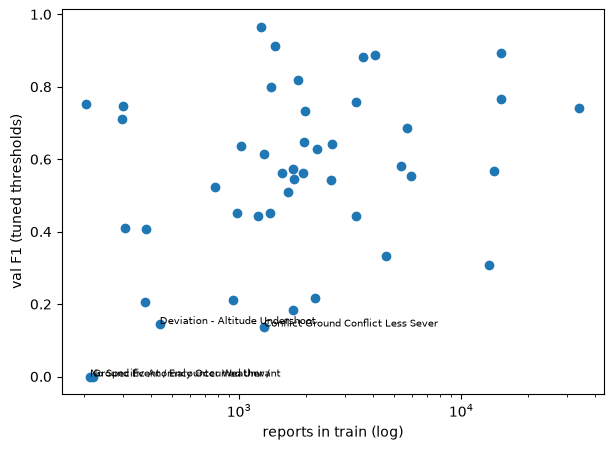

In [50]:
train_freq = pd.Series(y_train.sum(axis=0), index=labels)
f1 = pd.Series(per_label, index=labels)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(train_freq, f1)
for name in f1.nsmallest(4).index:
    ax.annotate(name[:35], (train_freq[name], f1[name]), fontsize=7)
ax.set_xscale("log")
ax.set_xlabel("reports in train (log)"); ax.set_ylabel("val F1 (tuned thresholds)")
plt.show()

### Conclusion

Frequency only weakly predicts F1 (Spearman correlation 0.34). Some frequent labels score badly: "Aircraft Equipment Problem Less Severe" has 13,281 training reports but F1 = 0.31, because separating *Critical* from *Less Severe* needs an understanding of how serious the event was, not just which words appear. Some rare labels score well when their vocabulary is distinctive (UAS 0.75 and bird strikes 0.75, with about 200-300 reports each).

- **Best:** Hazmat violation (0.97), wake vortex (0.91), equipment critical (0.89). Each has distinctive vocabulary.
- **Worst:** `Ground Event Weather / Turbulence` and `No Specific Anomaly Occurred Unwanted Situation` at 0.0, and the vague `Other / Unknown` labels around 0.2.
- **Where an LLM should help:** labels that depend on meaning rather than keywords, like severity (Critical vs Less Severe), the vague "Other / Unknown" categories, and "Unwanted Situation" (0.0, only 213 training reports from 2020-2022).

---

## 5. Base model and tokenization

A language model only reads numbers. The tokenizer cuts text into pieces (tokens) and maps each to an ID in a fixed vocabulary of ~150k entries. It must be the model’s own tokenizer, since the model learned what each ID means during pretraining. Batches must be rectangles, so short texts are padded (masked out by `attention_mask`) and long ones truncated at `max_length`. This section measures narrative lengths in tokens to choose `max_length`.

### 5.1 Load the tokenizer.

In [51]:
MODEL_NAME = "Qwen/Qwen3-0.6B-Base"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
train = pd.read_parquet(DATA_DIR / "train.parquet")
val = pd.read_parquet(DATA_DIR / "val.parquet")

In [52]:
print("vocab size:", len(tokenizer))
print("pad token:", tokenizer.pad_token, "| padding side:", tokenizer.padding_side)

vocab size: 151669
pad token: <|endoftext|> | padding side: right


### 5.2 See what tokens look like.

In [53]:
text = "On climbout at approx 15000 FT, ATC cleared us to FL340."
ids = tokenizer(text, add_special_tokens=False)["input_ids"]
print(len(text.split()), "words ->", len(ids), "tokens")
print(ids)
print(tokenizer.convert_ids_to_tokens(ids))
print(tokenizer.decode(ids))

11 words -> 23 tokens
[1925, 25367, 411, 518, 9848, 220, 16, 20, 15, 15, 15, 23301, 11, 7369, 34, 22949, 601, 311, 12772, 18, 19, 15, 13]
['On', 'Ġclimb', 'out', 'Ġat', 'Ġapprox', 'Ġ', '1', '5', '0', '0', '0', 'ĠFT', ',', 'ĠAT', 'C', 'Ġcleared', 'Ġus', 'Ġto', 'ĠFL', '3', '4', '0', '.']
On climbout at approx 15000 FT, ATC cleared us to FL340.


- `convert_ids_to_tokens` shows the pieces. A `Ġ` at the start of a piece means “this piece starts with a space”.
- `decode` turns the IDs back into the original text, which proves nothing is lost.
- If we look at how “FL340” and “15000” are split we can see that each digit becomes a token. We can conclude that this specific aviation jargon costs more tokens per word than normal English text.

### 5.3 Padding and truncation on a tiny batch

In [54]:
batch = tokenizer(
    ["Bird strike on takeoff.", "Smoke in the cabin during descent, we declared an emergency."],
    padding=True, truncation=True, max_length=10, add_special_tokens=False,
)
for ids, mask in zip(batch["input_ids"], batch["attention_mask"]):
    print(ids)
    print(mask, "\n")

[65270, 13169, 389, 1896, 1847, 13, 151643, 151643, 151643, 151643]
[1, 1, 1, 1, 1, 1, 0, 0, 0, 0] 

[76880, 304, 279, 13386, 2337, 36952, 11, 582, 14275, 458]
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1] 



- The short sentence gets padding at the end, with mask 0 for those positions.
- The long one is cut at 10 tokens.

**Qwen pads on the right.** Section 6 will need to find the last real token, not the last position.

### 5.4 Count tokens per narrative.

In [55]:
def token_lengths(texts):
    ids = tokenizer(list(texts), add_special_tokens=False)["input_ids"]
    return np.array([len(x) for x in ids])

train["n_tokens"] = token_lengths(train["narrative"])
val["n_tokens"] = token_lengths(val["narrative"])

### 5.5 Distribution and truncation rate.

In [56]:
for name, s in [("train", train), ("val", val)]:
    n = s["n_tokens"]
    print(name, "median", int(n.median()), "| p90", int(n.quantile(0.9)), "| p95", int(n.quantile(0.95)), "| max", n.max())
    for L in [256, 384, 512, 768]:
        print(f"   > {L}: {(n > L).mean():.1%} truncated")

train median 278 | p90 664 | p95 840 | max 3547
   > 256: 54.4% truncated
   > 384: 32.1% truncated
   > 512: 18.5% truncated
   > 768: 6.6% truncated
val median 233 | p90 599 | p95 772 | max 2769
   > 256: 45.4% truncated
   > 384: 24.9% truncated
   > 512: 14.5% truncated
   > 768: 5.0% truncated


### 5.6 Drift in length.
Does length drift over time?

In [57]:
train.groupby("year")["n_tokens"].median()

year
2010    273.5
2011    268.0
2012    276.0
2013    292.0
2014    309.0
2015    305.0
2016    307.0
2017    304.0
2018    281.0
2019    273.0
2020    251.0
2021    249.0
2022    230.0
Name: n_tokens, dtype: float64

### 5.7 Choice of `max_length`
- About 1.3 tokens per word (median 214 words vs 278 tokens), mainly because digits and jargon are split into many tokens.
- Median length decreases from about 305 tokens (2014-2017) to 230 (2022), and val is at 233. Test (2024-2025) should be similar or shorter.
- At 512 tokens, 14.5% of val is truncated; at 768, 5% but each training step costs about 1.5x more.

We use **`max_length = 512`**. Truncated reports keep their first ~400 words, where the event is usually described. In the error analysis we compare F1 on truncated vs full-length reports to check whether this choice costs anything.

In [58]:
MAX_LENGTH = 512

---

## 6. LoRA model: wrapper and sanity checks

### 6.1 Load the model

In [ ]:
import torch
from transformers import AutoModel

device = "mps" if torch.backends.mps.is_available() else "cpu"
model = AutoModel.from_pretrained(MODEL_NAME).to(device)
model.eval()
    
print("device:", device, "| dtype:", model.dtype)
print("layers:", model.config.num_hidden_layers, "| hidden size:", model.config.hidden_size)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.0f}M parameters")

W1109 21:52:14.278000 56450 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.19GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

device: mps | dtype: torch.bfloat16
layers: 28 | hidden size: 1024
596M parameters


### 6.2 One forward pass

In [61]:
batch = tokenizer(
    ["Bird strike on takeoff.", "Smoke in the cabin during descent, we declared an emergency."],
    padding=True, return_tensors="pt",
).to(device)

with torch.no_grad():
    out = model(**batch)

h = out.last_hidden_state
print(h.shape)  # (reports, tokens, hidden size)

torch.Size([2, 12, 1024])


### 6.3 Take the last real token of each report

In [ ]:
last_idx = batch["attention_mask"].sum(dim=1) - 1
pooled = h[torch.arange(h.size(0)), last_idx]
print("last real token positions:", last_idx.tolist())
print(pooled.shape)  # (reports, hidden size)

### 6.4 An untrained head

In [ ]:
head = torch.nn.Linear(model.config.hidden_size, len(labels)).to(device)
probs = torch.sigmoid(head(pooled))
print(probs.shape)  # (reports, 46)
print(probs[0, :5])